# Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New Jersey and Pennsylvania

本工作簿复现 David Card 与 Alan B. Krueger 的经典论文 *Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New Jersey and Pennsylvania*（AER, 1994）中的：

- **表 2** — 各变量均值（按州，分第一波/第二波）
- **表 3** — 每家门店平均就业人数（最低工资上调前后 + 双重差分 DiD）
- **表 4** — 就业变化的简化式（reduced-form）回归
- **图 1** — 起始工资（starting wage）分布，新泽西 vs 宾夕法尼亚，上调前 vs 上调后

**研究背景**：1992 年 4 月，新泽西州把最低工资从 \$4.25/小时提高到 \$5.05/小时；邻近的宾夕法尼亚州不变，作为对照组。作者对 410 家快餐店做了两轮调查（第一波 1992 年 2 月，第二波 1992 年 11–12 月），检验最低工资上调是否减少了就业。

**数据**：`public.csv`（与 notebook 同目录），410 个观测、46 列。空白表示缺失。

从上到下依次运行每个单元格即可。每节标注了 **输入 → 操作 → 输出**。


## 0. 读入数据与准备

**本部分涉及的 CSV 原始变量**：全部 46 列（读取整份 `public.csv`，统一清洗：空白 → NaN → 数值型）。

**输入**：`public.csv`。**操作**：读入 CSV，把空白当作缺失值（NaN），全部转为数值。**输出**：`df`（410 行 × 46 列）。

关键变量（详见 DATA_DICTIONARY）：
- `STATE`：1 = 新泽西(NJ)，0 = 宾夕法尼亚(PA)
- `EMPFT`/`EMPPT`/`NMGRS`：第一波 全职/兼职/经理人数；`EMPFT2`/`EMPPT2`/`NMGRS2` 为第二波
- `WAGE_ST`/`WAGE_ST2`：起始工资（美元/小时）
- `STATUS2`：第二波状态（0 拒绝、1 完成、2/4/5 临时关闭、3 永久关闭）
- `CHAIN`：1=BK、2=KFC、3=Roy Rogers、4=Wendy's


In [ ]:
# ===== SETUP：读入数据 =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

DATA = "public.csv"   # 如路径不同，请修改这里
df = pd.read_csv(DATA)

# 空白字符串 -> NaN，再统一转成数值
df = df.replace(r"^\s*$", np.nan, regex=True)
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("观测数(门店):", len(df), "| 列数:", df.shape[1])
print("按州分布:")
display(df["STATE"].value_counts().rename({1: "新泽西 NJ", 0: "宾夕法尼亚 PA"}).to_frame("门店数"))


## 1. 构造变量

**本部分涉及的 CSV 原始变量**：`STATE`、`WAGE_ST`、`EMPFT`、`EMPPT`、`NMGRS`、`EMPFT2`、`EMPPT2`、`NMGRS2`、`PSODA`、`PFRY`、`PENTREE`、`PSODA2`、`PFRY2`、`PENTREE2`、`CHAIN`。

**输入**：`df`。**操作**：
- **全职当量就业** FTE = 全职 + 经理 + 0.5 × 兼职（兼职按半个全职计）
- 永久关闭的门店（`STATUS2==3`）第二波就业设为 0；临时关闭（`STATUS2∈{2,4,5}`）保持缺失
- `demp` = 第二波 FTE − 第一波 FTE（就业变化）
- `gap` = 为达到新最低工资所需的工资涨幅（初始工资缺口），PA 或初始工资≥5.05 时为 0
- 其它：全职占比、套餐价格、按州×工资档的分组

**输出**：`df` 新增列 `fte1`、`fte2`、`demp`、`gap`、`fracft`、`fracft2`、`pmeal`、`pmeal2`、`group`、`chain_name`。


In [18]:
# ===== 1a. 全职当量就业（FTE）=====
# 兼职按 0.5 个全职计；经理计入全职
df["fte1"] = df["EMPFT"] + df["NMGRS"] + 0.5 * df["EMPPT"]     # 第一波
df["fte2"] = df["EMPFT2"] + df["NMGRS2"] + 0.5 * df["EMPPT2"]   # 第二波
# 永久关闭的门店(STATUS2==3)第二波就业在数据中已是 0；临时关闭(2,4,5)保持缺失
df["demp"] = df["fte2"] - df["fte1"]      # 就业变化

# ===== 1b. 初始工资缺口 gap =====
# gap = 0（PA 或 NJ 初始工资 >= 5.05）；否则 = (5.05 - wage_st)/wage_st
df["gap"] = np.nan
df.loc[df["STATE"] == 0, "gap"] = 0.0
nj = df["STATE"] == 1
df.loc[nj & (df["WAGE_ST"] >= 5.05), "gap"] = 0.0
df.loc[nj & (df["WAGE_ST"] > 0) & (df["WAGE_ST"] < 5.05), "gap"] = (5.05 - df["WAGE_ST"]) / df["WAGE_ST"]

# ===== 1c. 其它派生变量 =====
df["fracft"] = df["EMPFT"] / df["fte1"]      # 全职占比（按 FTE 口径）
df["fracft2"] = df["EMPFT2"] / df["fte2"]
df["pmeal"] = df["PSODA"] + df["PFRY"] + df["PENTREE"]    # 套餐价格 = 汽水+薯条+主菜
df["pmeal2"] = df["PSODA2"] + df["PFRY2"] + df["PENTREE2"]

# ===== 1d. 按 州×初始工资档 分组（用于表3）=====
def wage_group(r):
    if r["STATE"] == 0:
        return "PA"
    if r["WAGE_ST"] == 4.25:
        return "NJ_low"
    if 4.25 < r["WAGE_ST"] < 5.00:
        return "NJ_mid"
    if r["WAGE_ST"] >= 5.00:
        return "NJ_high"
    return "NJ_missing"
df["group"] = df.apply(wage_group, axis=1)

df["chain_name"] = df["CHAIN"].map({1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy's"})
print("FTE 第一波均值(全体): %.3f | 第二波均值(全体): %.3f" % (df["fte1"].mean(), df["fte2"].mean()))
print("就业变化 demp: 均值 %.3f | 标准差 %.3f" % (df["demp"].mean(), df["demp"].std(ddof=1)))


FTE 第一波均值(全体): 20.999 | 第二波均值(全体): 21.054
就业变化 demp: 均值 -0.070 | 标准差 9.022


## 2. 表 2 — 各变量均值（按州）

**本部分涉及的 CSV 原始变量**：`STATE`、`CHAIN`、`CO_OWNED`、`WAGE_ST`、`WAGE_ST2`、`STATUS2`、`HRSOPEN`、`HRSOPEN2`、`BONUS`、`SPECIAL2`（另用到第 1 节派生的 `fte1`、`fte2`、`fracft`、`fracft2`、`pmeal`、`pmeal2`）。

**输入**：`df`。**操作**：分 NJ / PA 计算各变量的均值（对非缺失观测），给出标准误（= 标准差/√n），以及 NJ−PA 均值相等性检验的 t 统计量。**输出**：表 2。

说明：论文中的"百分比全职"= 全职人数 / 全职当量（`EMPFT/FTE`），套餐价格 = 汽水+薯条+主菜三样之和，第二波的"招募奖金"用 `SPECIAL2`。


In [19]:
# ===== 2a. 门店类型分布（百分比，按州）+ 均值相等性检验 =====
# 变量：Burger King / KFC / Roy Rogers / Wendy's（占该州门店比例），以及公司直营占比
def pct_ttest(mask):
    """对 0/1 指示变量检验 NJ 与 PA 的占比(均值)是否相等，返回 (NJ%, PA%, t)"""
    v_nj, v_pa = mask[df.STATE == 1], mask[df.STATE == 0]
    p_nj, p_pa = v_nj.mean(), v_pa.mean()
    se_nj = v_nj.std(ddof=1) / np.sqrt(len(v_nj))
    se_pa = v_pa.std(ddof=1) / np.sqrt(len(v_pa))
    t = (p_nj - p_pa) / np.sqrt(se_nj**2 + se_pa**2)
    return 100 * p_nj, 100 * p_pa, t

vars_ = {
    "Burger King": (df["CHAIN"] == 1),
    "KFC":         (df["CHAIN"] == 2),
    "Roy Rogers":  (df["CHAIN"] == 3),
    "Wendy's":     (df["CHAIN"] == 4),
    "Company owned": (df["CO_OWNED"] == 1),
}

tab2a = pd.DataFrame([(name, *pct_ttest(mask)) for name, mask in vars_.items()],
                     columns=["Variable", "NJ", "PA", "t-statistic"])
print("门店类型分布（占该州门店总数的百分比，单位：百分点）")
display(tab2a.round(2))

门店类型分布（占该州门店总数的百分比，单位：百分点）


,Variable,NJ,PA,t-statistic
0,Burger King,41.09,44.30,-0.52
1,KFC,20.54,15.19,1.16
2,Roy Rogers,24.77,21.52,0.62
3,Wendy's,13.60,18.99,-1.12
4,Company owned,34.14,35.44,-0.22


In [ ]:
# ===== 2b. 各变量均值（mean (se)，按州）+ 均值相等性检验 =====
# 先构造指示变量（0/1），用于百分比型变量
df["at425"]   = (df["WAGE_ST"]  == 4.25).astype(float)
df["at425_2"] = (df["WAGE_ST2"] == 4.25).astype(float)
# 临时关闭门店(STATUS2∈{2,4,5})不计入第二波工资分布，以对齐论文的 85.2%（否则公开数据会多算一家，得 85.5%）
df["at505_2"] = ((df["WAGE_ST2"] == 5.05) & ~df["STATUS2"].isin([2, 4, 5])).astype(float)

# 注：第二波 NJ 的「工资=$4.25」比例为精确的 0（每家店第二波工资都 ≥$5.05 或已关闭），
# 该组方差=0、标准误=0。此时两样本 t 检验退化（Welch–Satterthwaite 自由度无定义，
# 分母只剩另一组的标准误，实际是在检验"PA 是否=0"而非"NJ=PA"），故论文该行 t 记作 '—'。
# 下面的 mean_se_t 对任一组方差为 0 的情形同样输出 '—'，以对齐论文。
def mean_se_t(varname, pct=False):
    """返回 (NJ, PA, t)，其中 NJ/PA 为 '均值 (标准误)'；百分比型变量数值 ×100（百分点）。
    当某一组方差为 0（无抽样误差）时，t 检验退化，t 输出 '—'。"""
    v_nj = df.loc[df.STATE == 1, varname].dropna()
    v_pa = df.loc[df.STATE == 0, varname].dropna()
    se_nj = v_nj.std(ddof=1) / np.sqrt(len(v_nj))
    se_pa = v_pa.std(ddof=1) / np.sqrt(len(v_pa))
    k = 100 if pct else 1
    if se_nj == 0 or se_pa == 0:
        t = "—"
    else:
        t = round((v_nj.mean() - v_pa.mean()) / np.sqrt(se_nj**2 + se_pa**2), 2)
    return f"{k*v_nj.mean():.2f} ({k*se_nj:.2f})", f"{k*v_pa.mean():.2f} ({k*se_pa:.2f})", t

def make_table(vars_dict):
    return pd.DataFrame(
        [(name, *mean_se_t(var, pct)) for name, (var, pct) in vars_dict.items()],
        columns=["Variable", "NJ", "PA", "t-statistic"],
    )

wave1 = {
    "FTE employment":                 ("fte1",     False),
    "Percentage full-time employees": ("fracft",   True),
    "Starting wage":                  ("WAGE_ST",  False),
    "Wage = $4.25 (%)":               ("at425",    True),
    "Price of full meal":             ("pmeal",    False),
    "Hours open (weekday)":           ("HRSOPEN",  False),
    "Recruiting bonus (%)":           ("BONUS",    True),
}

wave2 = {
    "FTE employment":                 ("fte2",     False),
    "Percentage full-time employees": ("fracft2",  True),
    "Starting wage":                  ("WAGE_ST2", False),
    "Wage = $4.25 (%)":               ("at425_2",  True),
    "Wage = $5.05 (%)":               ("at505_2",  True),
    "Price of full meal":             ("pmeal2",   False),
    "Hours open (weekday)":           ("HRSOPEN2", False),
    "Recruiting bonus (%)":           ("SPECIAL2", True),
}

print("表 2 — 第 1 波 (February 1992)：NJ/PA 单元格 = 均值 (标准误)")
display(make_table(wave1))
print("表 2 — 第 2 波 (November 1992)：NJ/PA 单元格 = 均值 (标准误)")
display(make_table(wave2))
print("注：第二波 NJ 的「工资=$4.25」为精确的 0%（无 NJ 门店在第二波仍支付 $4.25），"
      "该组方差为 0、无抽样误差，两样本 t 检验退化，故该行 t 记作 '—'（论文同）。")

## 3. 图 1 — 起始工资分布

**本部分涉及的 CSV 原始变量**：`STATE`、`WAGE_ST`、`WAGE_ST2`。

**输入**：`df` 的 `WAGE_ST`（第一波）与 `WAGE_ST2`（第二波）。**操作**：画 1×2 两幅图——1992 年 2 月 / 1992 年 11 月；每幅图把同一时期的新泽西（黑色实心柱）与宾夕法尼亚（斜线填充柱）在同一刻度下并排显示（互不覆盖）。横轴为 Wage Range（断轴：先 0，再 4.25–5.55，刻度 0.1），纵轴为 Percent of stores（百分比；2 月 0–35、刻度 5，11 月 0–90、刻度 10）。**输出**：图 1。

核心发现：第一波两州起始工资分布几乎重合；第二波新泽西的分布整体右移、集中在 $5.05，而宾夕法尼亚基本不变。


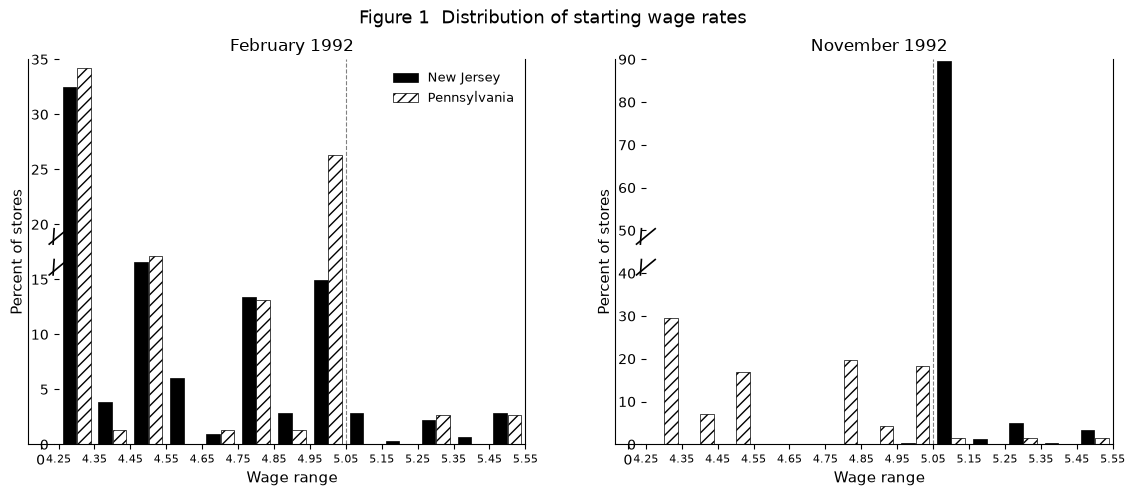

In [20]:
# ===== 图1：起始工资分布（两面板：Feb / Nov；每面板 NJ 与 PA 同刻度并排；横轴断轴 0 — 4.25—5.55）=====
import matplotlib.gridspec as gridspec

wage_lo, wage_hi = 4.25, 5.55
bins = np.arange(425, 556, 10) / 100.0   # 0.1 宽桶：4.25, 4.35, ..., 5.55（整数构造避免浮点漂移）
centers = (bins[:-1] + bins[1:]) / 2.0   # 桶中心：4.30, 4.40, ..., 5.50

panels = [("WAGE_ST",  "February 1992", 35, 5),
          ("WAGE_ST2", "November 1992", 90, 10)]

fig = plt.figure(figsize=(14, 5))
gs_outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.18)

for gi, (gs, (var, title, ymax, ystep)) in enumerate(zip(gs_outer, panels)):
    # 每个面板拆成 左窄轴(只显示 0) + 右宽轴(4.25–5.55)，两者共享纵轴 → 断轴
    gs_in = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs,
                                             width_ratios=[1, 18], wspace=0.02)
    ax0 = fig.add_subplot(gs_in[0])   # 只画 "0"
    ax  = fig.add_subplot(gs_in[1])   # 画 4.25–5.55 的直方图

    # NJ 与 PA 在同一桶内并排（不互相覆盖）：NJ 黑色实心、PA 白色斜线填充
    bar_w, dx = 0.038, 0.020
    for st, face, hatch, lab, shift in [(1, "black", None,  "New Jersey",   -dx),
                                        (0, "white", "///", "Pennsylvania", +dx)]:
        s = df.loc[df.STATE == st, var].dropna().clip(lower=wage_lo, upper=wage_hi)
        cnt, _ = np.histogram(s, bins=bins)
        pct = 100.0 * cnt / len(s)                    # 占该州门店的百分比
        ax.bar(centers + shift, pct, width=bar_w, facecolor=face, edgecolor="black",
               hatch=hatch, linewidth=0.5, label=lab)

    ax.axvline(5.05, color="gray", lw=0.8, ls="--")   # 新最低工资参考线

    # —— 右轴：横轴 4.25–5.55（刻度 0.1）；纵轴按面板 ——
    ax.set_xlim(wage_lo, wage_hi)
    ax.set_xticks(bins)
    ax.tick_params(axis="x", labelsize=8)
    ax.set_ylim(0, ymax)
    ax.set_yticks(np.arange(0, ymax + 1, ystep))
    ax.set_xlabel("Wage range", fontsize=11)
    ax.set_ylabel("Percent of stores", fontsize=11)
    ax.set_title(title, fontsize=12)
    if gi == 0:
        ax.legend(loc="upper right", fontsize=9, frameon=False)

    # —— 左轴：只显示 "0" ——
    ax0.set_xlim(-0.15, 0.15)
    ax0.set_xticks([0.0])
    ax0.set_ylim(0, ymax)
    ax0.set_yticks([])
    ax0.tick_params(axis="y", left=False, labelleft=False)

    # 断轴处理：隐藏相接的脊，留出断口，画 "//" 斜线
    ax0.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax0.spines["top"].set_visible(False)
    ax.spines["top"].set_visible(False)
    d = 0.02
    for a, xf in [(ax0, 1.0), (ax, 0.0)]:
        for y0 in (0.46, 0.54):
            a.plot([xf - d, xf + d], [y0 - d, y0 + d], transform=a.transAxes,
                   color="k", lw=1.2, clip_on=False)

fig.suptitle("Figure 1  Distribution of starting wage rates", fontsize=13)
plt.show()


## 4. 表 3 — 平均就业与双重差分（DiD）

**本部分涉及的 CSV 原始变量**：`STATE`、`WAGE_ST`、`EMPFT`、`EMPPT`、`NMGRS`、`EMPFT2`、`EMPPT2`、`NMGRS2`、`STATUS2`（经第 1 节派生的 `fte1`、`fte2`、`group` 使用）。

**输入**：`df`。**操作**：分 5 个组（PA、NJ、NJ 低薪/中档/高薪）计算：

- 行 1：第一波 FTE 均值（全部可用观测）
- 行 2：第二波 FTE 均值（全部可用观测，永久关闭店 = 0）
- 行 3：平均 FTE 的变化 = 行 2 − 行 1（非平衡）
- 行 4：变化（平衡样本，即两波都有数据的门店）
- 行 5：变化（临时关闭店第二波就业设为 0）

并计算差异列：NJ−PA（DiD）、低薪−高薪、中档−高薪。**输出**：表 3。

> 注：行 3 的"变化"= 两波均值之差（非平衡），其标准误按配对样本（同一批门店两波之差）计算；论文该行报告的标准误（NJ 0.54、PA 1.25、DiD 1.36）与本表的配对标准误（NJ 0.48、PA 1.25、DiD 1.34）略有出入，但由此得到的 **DiD t 统计量 ≈ 2.03，与论文一致**。行 1、2、4、5 与论文完全一致。


In [21]:
# ===== 表3 计算 =====
groups = {"PA": ("宾夕法尼亚 PA", df.STATE == 0),
          "NJ": ("新泽西 NJ", df.STATE == 1),
          "NJ_low": ("NJ 低薪 $4.25", df.group == "NJ_low"),
          "NJ_mid": ("NJ 中档 $4.26-4.99", df.group == "NJ_mid"),
          "NJ_high": ("NJ 高薪 ≥$5.00", df.group == "NJ_high")}

def rstat(mask):
    """对某个组返回 行1~行5 的 (mean, se)"""
    g = df.loc[mask]
    m1, se1 = g["fte1"].mean(), g["fte1"].std(ddof=1) / np.sqrt(g["fte1"].count())
    m2, se2 = g["fte2"].mean(), g["fte2"].std(ddof=1) / np.sqrt(g["fte2"].count())
    # 行4: 平衡样本（两波都有数据的门店）——这是 DiD 的标准样本
    bal = g.loc[g.fte1.notna() & g.fte2.notna()]
    d4 = (bal["fte2"] - bal["fte1"])
    m4, se4 = d4.mean(), d4.std(ddof=1) / np.sqrt(len(d4))
    # 行3: 非平衡两波均值之差，标准误用配对样本（同一批门店两波之差）
    chg3 = m2 - m1
    se3 = se4
    # 行5: 临时关闭店第二波=0（只对 STATUS2∈{2,4,5} 设0，其余缺失保持缺失）
    base5 = g.loc[g.fte1.notna() & (g.fte2.notna() | g.STATUS2.isin([2, 4, 5]))].copy()
    base5["fte2_5"] = base5["fte2"].where(base5["fte2"].notna(), 0.0)
    d5 = base5["fte2_5"] - base5["fte1"]
    m5, se5 = d5.mean(), d5.std(ddof=1) / np.sqrt(len(d5))
    return [(m1, se1), (m2, se2), (chg3, se3), (m4, se4), (m5, se5)]

res = {k: rstat(v[1]) for k, v in groups.items()}

def fmt(pair):
    return f"{pair[0]:.2f} ({pair[1]:.2f})"

def diff(a, b):
    """两列之差及其标准误 = sqrt(se_a^2+se_b^2)"""
    return (a[0] - b[0], np.sqrt(a[1]**2 + b[1]**2))

rows_names = ["1. 第一波 FTE 就业（全部可用）",
              "2. 第二波 FTE 就业（全部可用）",
              "3. 平均 FTE 变化（非平衡）",
              "4. 平均 FTE 变化（平衡样本）",
              "5. 平均 FTE 变化（临时关闭店=0）"]

# 行 = 5 种统计量，列 = 8 个组（PA / NJ / NJ−PA / NJ 低薪 / NJ 中档 / NJ 高薪 / 低薪−高薪 / 中档−高薪）
tab3 = pd.DataFrame(index=rows_names)
for col, key in [("PA", "PA"), ("NJ", "NJ"), ("NJ−PA", None),
                 ("NJ 低薪$4.25", "NJ_low"), ("NJ 中档", "NJ_mid"),
                 ("NJ 高薪≥$5.00", "NJ_high"),
                 ("低薪−高薪", None), ("中档−高薪", None)]:
    if key is not None:
        vals = res[key]
    elif col == "NJ−PA":
        vals = [diff(res["NJ"][i], res["PA"][i]) for i in range(5)]
    elif col == "低薪−高薪":
        vals = [diff(res["NJ_low"][i], res["NJ_high"][i]) for i in range(5)]
    else:  # 中档−高薪
        vals = [diff(res["NJ_mid"][i], res["NJ_high"][i]) for i in range(5)]
    tab3[col] = [fmt(v) for v in vals]

print("表 3：每家门店平均就业人数（单元格 = 均值 (标准误)）")
display(tab3)


表 3：每家门店平均就业人数（单元格 = 均值 (标准误)）


,PA,NJ,NJ−PA,NJ 低薪$4.25,NJ 中档,NJ 高薪≥$5.00,低薪−高薪,中档−高薪
1. 第一波 FTE 就业（全部可用）,23.33 (1.35),20.44 (0.51),-2.89 (1.44),19.56 (0.77),20.08 (0.84),22.25 (1.14),-2.69 (1.37),-2.17 (1.41)
2. 第二波 FTE 就业（全部可用）,21.17 (0.94),21.03 (0.52),-0.14 (1.08),20.88 (1.01),20.96 (0.76),20.21 (1.03),0.66 (1.44),0.74 (1.27)
3. 平均 FTE 变化（非平衡）,-2.17 (1.25),0.59 (0.48),2.75 (1.34),1.32 (0.82),0.87 (0.69),-2.04 (1.01),3.36 (1.30),2.91 (1.22)
4. 平均 FTE 变化（平衡样本）,-2.28 (1.25),0.47 (0.48),2.75 (1.34),1.20 (0.82),0.71 (0.69),-2.16 (1.01),3.36 (1.30),2.87 (1.22)
5. 平均 FTE 变化（临时关闭店=0）,-2.28 (1.25),0.23 (0.49),2.51 (1.35),0.90 (0.87),0.49 (0.69),-2.39 (1.02),3.29 (1.34),2.88 (1.23)


## 5. 表 4 — 就业变化的简化式回归

**本部分涉及的 CSV 原始变量**：`STATE`、`WAGE_ST`、`WAGE_ST2`、`EMPFT`、`EMPPT`、`NMGRS`、`EMPFT2`、`EMPPT2`、`NMGRS2`、`STATUS2`、`CHAIN`、`CO_OWNED`、`CENTRALJ`、`SOUTHJ`、`PA1`、`PA2`（经第 1 节派生的 `demp`、`gap` 使用）。

**输入**：`df` 中两波就业与工资都有效（或永久关闭）的门店（357 家）。**操作**：以就业变化 `demp` 为被解释变量，估计 5 个 OLS 模型：

| 列 | 设定 |
|---|---|
| (i) | NJ 虚拟变量 |
| (ii) | NJ 虚拟变量 + 连锁/直营控制 |
| (iii) | 初始工资缺口 GAP |
| (iv) | GAP + 连锁/直营控制 |
| (v) | GAP + 连锁/直营控制 + 地区虚拟变量 |

**输出**：表 4（6 行 × 6 列）——列 = `Independent variable` 与模型 (i)–(v)；行 = New Jersey dummy、Initial wage gap、Controls for chain and ownership（no/yes）、Controls for region（no/yes）、Standard error of regression、Probability value for controls。单元格为「系数（标准误）」；缺失系数记作 —。表后附论文脚注。


In [22]:
# ===== 表4 样本与回归（论文原表4版式：6 行 × 6 列）=====
df["dwage"] = df["WAGE_ST2"] - df["WAGE_ST"]
sub = df[df["demp"].notna() & ((df["STATUS2"] == 3) | df["dwage"].notna())].copy()

sub["bk"] = (sub["CHAIN"] == 1).astype(float)
sub["kfc"] = (sub["CHAIN"] == 2).astype(float)
sub["roys"] = (sub["CHAIN"] == 3).astype(float)

# 五个模型：关键变量 + 控制变量。
#   chain/ownership 控制 = bk, kfc, roys, CO_OWNED；region 控制 = CENTRALJ, SOUTHJ, PA1, PA2
#   注意：模型(v) = GAP + 连锁/直营(含 CO_OWNED) + 地区，共 8 个控制变量（论文表4 两行均标 yes）
specs = [
    ("(i)",   "STATE", []),
    ("(ii)",  "STATE", ["bk", "kfc", "roys", "CO_OWNED"]),
    ("(iii)", "gap",   []),
    ("(iv)",  "gap",   ["bk", "kfc", "roys", "CO_OWNED"]),
    ("(v)",   "gap",   ["bk", "kfc", "roys", "CO_OWNED", "CENTRALJ", "SOUTHJ", "PA1", "PA2"]),
]
labels = [s[0] for s in specs]

nj_cell, gap_cell, mse_cell, chain_cell, region_cell, p_cell = {}, {}, {}, {}, {}, {}
for label, key, ctrl in specs:
    X = sm.add_constant(sub[[key] + ctrl])
    fit = sm.OLS(sub["demp"], X).fit()
    cell = f"{fit.params[key]:.2f} ({fit.bse[key]:.2f})"
    (nj_cell if key == "STATE" else gap_cell)[label] = cell
    mse_cell[label] = f"{np.sqrt(fit.mse_resid):.2f}"
    chain_cell[label] = "yes" if any(c in ("bk", "kfc", "roys", "CO_OWNED") for c in ctrl) else "no"
    region_cell[label] = "yes" if any(c in ("CENTRALJ", "SOUTHJ", "PA1", "PA2") for c in ctrl) else "no"
    if ctrl:
        Xr = sm.add_constant(sub[[key]])
        fitr = sm.OLS(sub["demp"], Xr).fit()
        rss_f, rss_r = np.sum(fit.resid**2), np.sum(fitr.resid**2)
        df1, df2 = len(ctrl), int(fit.df_resid)
        F = ((rss_r - rss_f) / df1) / (rss_f / df2)
        p_cell[label] = f"{1 - stats.f.cdf(F, df1, df2):.2f}"
    else:
        p_cell[label] = "—"

def row_from(d):
    return [d.get(label, "—") for label in labels]

tab4 = pd.DataFrame(
    [["New Jersey dummy"] + row_from(nj_cell),
     ["Initial wage gap"] + row_from(gap_cell),
     ["Controls for chain and ownership"] + row_from(chain_cell),
     ["Controls for region"] + row_from(region_cell),
     ["Standard error of regression"] + row_from(mse_cell),
     ["Probability value for controls"] + row_from(p_cell)],
    columns=["Independent variable"] + labels,
).set_index("Independent variable")

print("表 4：就业变化的简化式回归（被解释变量 = FTE 就业变化；单元格 = 系数（标准误））")
display(tab4)

print("\nNotes:")
print("· Standard errors are given in parentheses. The sample consists of 357 stores with available")
print("  data on employment and starting wages in waves 1 and 2.")
print("· The dependent variable in all models is change in FTE employment. The mean and standard")
print("  deviation of the dependent variable are -0.237 and 8.825, respectively.")
print("· All models include an unrestricted constant (not reported).")
print("· “Initial wage gap” = proportional increase in starting wage necessary to raise starting wage")
print("  to the new minimum rate. For stores in Pennsylvania the wage gap is 0.")
print("· “Controls for chain and ownership” = three dummy variables for chain type and whether or not")
print("  the store is company-owned.")
print("· “Controls for region” = dummy variables for two regions of New Jersey and two regions of")
print("  eastern Pennsylvania.")
print("· “Probability value for controls” = probability value of joint F test for exclusion of all")
print("  control variables.")


表 4：就业变化的简化式回归（被解释变量 = FTE 就业变化；单元格 = 系数（标准误））


,(i),(ii),(iii),(iv),(v)
Independent variable,,,,,
New Jersey dummy,2.33 (1.19),2.30 (1.20),—,—,—
Initial wage gap,—,—,15.65 (6.08),14.92 (6.21),11.98 (7.42)
Controls for chain and ownership,no,yes,no,yes,yes
Controls for region,no,no,no,no,yes
Standard error of regression,8.79,8.78,8.76,8.76,8.75
Probability value for controls,—,0.34,—,0.44,0.40



Notes:
· Standard errors are given in parentheses. The sample consists of 357 stores with available
  data on employment and starting wages in waves 1 and 2.
· The dependent variable in all models is change in FTE employment. The mean and standard
  deviation of the dependent variable are -0.237 and 8.825, respectively.
· All models include an unrestricted constant (not reported).
· “Initial wage gap” = proportional increase in starting wage necessary to raise starting wage
  to the new minimum rate. For stores in Pennsylvania the wage gap is 0.
· “Controls for chain and ownership” = three dummy variables for chain type and whether or not
  the store is company-owned.
· “Controls for region” = dummy variables for two regions of New Jersey and two regions of
  eastern Pennsylvania.
· “Probability value for controls” = probability value of joint F test for exclusion of all
  control variables.


## 6. 结果核对与解读

跑完上述单元格后，把本表的数字与论文原文（表 2~4、图 1）对照。关键结果应吻合：

- **表 3**：NJ 第一波 FTE ≈ 20.44、第二波 ≈ 21.03；PA 第一波 ≈ 23.33、第二波 ≈ 21.17；DiD ≈ 2.75（论文正文记 2.76，t≈2.03）。
- **表 4**：NJ 虚拟变量系数 ≈ 2.33 (1.19)；GAP 系数 ≈ 15.65 (6.08)，加入控制后 ≈ 14.92 (6.21)、加入地区后 ≈ 11.98 (7.42)。
- **图 1**：第一波两州工资分布相近，第二波 NJ 明显右移并集中到 \$5.05。

**结论解读**：与"竞争性劳动市场"的预测相反，最低工资上调**没有**导致新泽西快餐业就业下降（相对 PA 甚至略有上升）。这一结论在后续文献中引发大量讨论（如 Neumark & Wascher 2000 的质疑与 Card & Krueger 2000 的回应）。
